<a href="https://colab.research.google.com/github/dhrishithagcd24-collab/DLG_LAB/blob/main/DLG_LAB_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Dhrishitha G

USN: 1BM24CD018

Program: 5

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import models, layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Load data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [2]:
PIXEL_MAX = 255.0

x_train = x_train.astype('float32') / PIXEL_MAX
x_test = x_test.astype('float32') / PIXEL_MAX

print("PIXEL_MAX is:", PIXEL_MAX)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

PIXEL_MAX is: 255.0
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [3]:
TIME_STEPS = 28
FEATURES = 28

x_train = x_train.reshape(-1, TIME_STEPS, FEATURES)
x_test = x_test.reshape(-1, TIME_STEPS, FEATURES)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)


In [4]:
NUM_CLASSES = 10

y_train = to_categorical(y_train, NUM_CLASSES)
y_test = to_categorical(y_test, NUM_CLASSES)

print("NUM_CLASSES:", NUM_CLASSES)
print("y_train shape:", y_train.shape)

NUM_CLASSES: 10
y_train shape: (60000, 10)


In [5]:
LSTM_UNITS = 128
OUT_UNITS = 10

model = models.Sequential()

# Q2a: LSTM layer with output units and input shape
model.add(
    layers.LSTM(
        LSTM_UNITS,
        activation='relu',
        input_shape=(TIME_STEPS, FEATURES)
    )
)

# Q2b: Output Dense Layer with softmax activation
model.add(
    layers.Dense(
        OUT_UNITS,
        activation='softmax'
    )
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,674 (319.04 KB)

 Trainable params: 81,674 (319.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
F = FEATURES
U = LSTM_UNITS

lstm_params = 4 * ((F + U) * U + U)
dense_params = (LSTM_UNITS * OUT_UNITS) + OUT_UNITS
total_params = lstm_params + dense_params

print("Calculated LSTM Parameters:", lstm_params)
print("Calculated Dense Parameters:", dense_params)
print("Calculated Total Parameters:", total_params)

Calculated LSTM Parameters: 80384
Calculated Dense Parameters: 1290
Calculated Total Parameters: 81674


In [7]:
# Q3a Compile
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
# Q3b Train
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.8279 - loss: 0.5360 - val_accuracy: 0.9514 - val_loss: 0.1609
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9602 - loss: 0.1304 - val_accuracy: 0.9704 - val_loss: 0.0983
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9727 - loss: 0.0906 - val_accuracy: 0.9708 - val_loss: 0.0957
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9771 - loss: 0.0740 - val_accuracy: 0.9761 - val_loss: 0.0742
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9818 - loss: 0.0586 - val_accuracy: 0.9812 - val_loss: 0.0619
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9845 - loss: 0.0506 - val_accuracy: 0.9836 - val_loss: 0.0474
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9857 - loss: 0.0459 - val_accuracy: 0.9864 - val_loss: 0.0447
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9876 - loss: 0.0410 - val_accuracy: 

In [9]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Final Test Loss: {loss:.4f}")
print(f"Final Test Accuracy: {accuracy * 100:.2f}%")

Final Test Loss: 0.0450
Final Test Accuracy: 98.64%


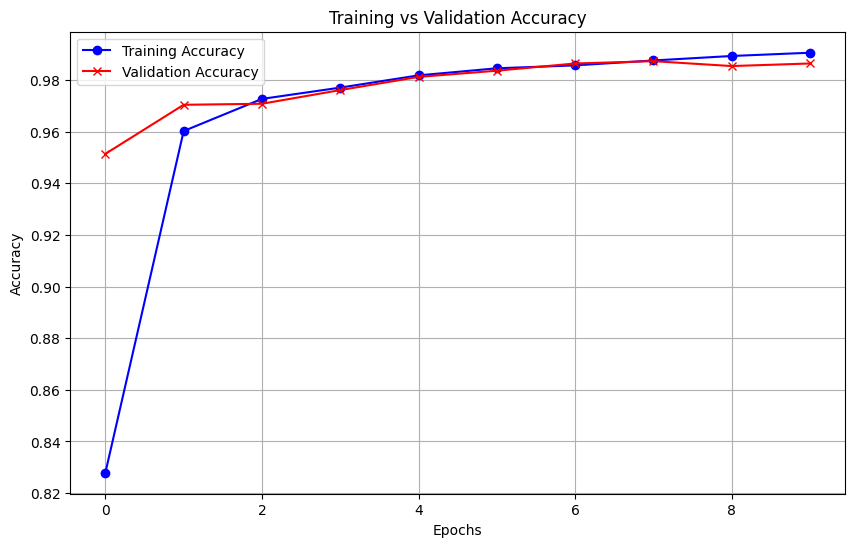

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='red', marker='x')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()